# SDF, Marching Squares i Marching Cubes

W tym notebooku możesz przetestować interaktywne demonstracje SDF, Marching Squares i Marching Cubes.

Na końcu, tuż przed źródłami, znajdziesz krótkie **zadanie domowe**.

In [10]:
from functools import lru_cache
from inspect import getsource
from time import perf_counter

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import Code, display
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from skimage.measure import marching_cubes

from scripts.utils import marching_squares as ms

%matplotlib inline

BG, INK = "#F8FAFC", "#0F172A"
BLUE, ORANGE, TEAL = "#2563EB", "#EA580C", "#0F766E"
SECONDARY, GRAY, GRID = "#64748B", "#94A3B8", "#CBD5E1"
SDF_CMAP = LinearSegmentedColormap.from_list("sdf", [BLUE, BG, ORANGE], N=257)
DOMAIN_2D = (-1.8, 1.8)
DENSE = np.linspace(*DOMAIN_2D, 301)
X, Y = np.meshgrid(DENSE, DENSE)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "mathtext.fontset": "dejavusans",
    "figure.facecolor": BG,
    "axes.facecolor": BG,
    "text.color": INK,
    "axes.labelcolor": INK,
    "axes.edgecolor": GRAY,
    "axes.titlecolor": INK,
    "xtick.color": SECONDARY,
    "ytick.color": SECONDARY,
    "grid.color": GRID,
    "figure.dpi": 115,
})


def field_map(ax, x, y, values, limit):
    '''Wspólna skala barw z bielą w zerze.'''
    return ax.pcolormesh(
        x, y, values, shading="auto", cmap=SDF_CMAP, vmin=-limit, vmax=limit
    )


def draw_level(ax, x, y, values, level=0, color=INK, linestyle="solid"):
    if values.min() < level < values.max():
        ax.contour(x, y, values, levels=[level], colors=[color],
                   linewidths=1.8, linestyles=linestyle)


def plane_axes(ax, title, limits=DOMAIN_2D, labels=("x", "y")):
    ax.set(title=title, xlim=limits, ylim=limits, aspect="equal",
           xlabel=labels[0], ylabel=labels[1])


def show_figure(fig):
    display(fig)
    plt.close(fig)


def float_slider(label, value, minimum, maximum, step=0.05):
    return widgets.FloatSlider(
        description=label, value=value, min=minimum, max=maximum, step=step,
        continuous_update=False, style={"description_width": "initial"},
    )

## 1. Signed Distance Function w 2D

Dla okręgu o środku $C=(c_x,c_y)$ i promieniu $r$ pole odległości ze znakiem ma postać

$$f(x,y)=\sqrt{(x-c_x)^2+(y-c_y)^2}-r.$$

Wewnątrz $f<0$, na brzegu $f=0$, na zewnątrz $f>0$. Długość odcinka od $P$ do najbliższego punktu $Q$ na brzegu wynosi $|f(P)|$. Gdy $P=C$, wszystkie punkty okręgu są równie bliskie. Wykres pokazuje wtedy punkt na prawo od środka.

In [11]:
def circle_sdf(x, y, center=(0, 0), radius=1.0):
    cx, cy = center
    return np.hypot(x - cx, y - cy) - radius


def closest_on_circle(point, center, radius):
    offset = np.asarray(point) - center
    distance = np.linalg.norm(offset)
    direction = np.array([1.0, 0.0]) if distance == 0 else offset / distance
    return np.asarray(center) + radius * direction


def draw_circle_demo(radius, px, py):
    center = (0, 0)
    point = np.array([px, py])
    nearest = closest_on_circle(point, center, radius)
    value = circle_sdf(px, py, center, radius)
    fig, ax = plt.subplots(figsize=(6.4, 4.4), layout="constrained")
    values = circle_sdf(X, Y, center, radius)
    image = field_map(ax, X, Y, values, 1.8)
    draw_level(ax, X, Y, values)
    ax.plot(*np.stack((point, nearest)).T, color=INK, linestyle="--",
            linewidth=2.4, label=r"Odcinek $PQ$")
    ax.scatter(*nearest, marker="D", s=82, color=TEAL, edgecolor=BG,
               zorder=4, label="Q · najbliższy punkt")
    ax.scatter(*point, s=35, color=INK, edgecolor=BG, zorder=5, label="P")
    plane_axes(ax, f"f(P) = {value:+.3f}     |PQ| = {abs(value):.3f}")
    fig.colorbar(image, ax=ax, label="Wartość SDF", shrink=0.83, extend="both")
    ax.legend(loc="upper left", fontsize=8)
    show_figure(fig)


circle_controls = {
    "radius": float_slider("Promień r", 1.0, 0.25, 1.35),
    "px": float_slider("x punktu P", 1.25, -1.6, 1.6),
    "py": float_slider("y punktu P", 0.45, -1.6, 1.6),
}
display(widgets.VBox([
    widgets.VBox(list(circle_controls.values())),
    widgets.interactive_output(draw_circle_demo, circle_controls),
]))

## 2. Operacje na polach SDF

Znak pola określa, do której części płaszczyzny należy punkt. Z tego wynika zapis operacji na wnętrzach dwóch okręgów o polach $f_1$ i $f_2$.

| Operacja | Pole wyniku |
| --- | --- |
| Suma | $\min(f_1,f_2)$ |
| Przecięcie | $\max(f_1,f_2)$ |
| Różnica | $\max(f_1,-f_2)$ |

Przy typowym przecięciu okręgów granica wyniku biegnie tam, gdzie znak pola zmienia się przez zero. Przy styczności lub pokrywaniu się granic mogą wystąpić zera bez zmiany znaku. Przykładowo różnica dwóch identycznych okręgów ma puste wnętrze i pole $|f_1|$. Po złożeniu pól ich wartości mogą odbiegać od dokładnej odległości euklidesowej do nowej granicy.

In [12]:
def combine_fields(first, second, operation):
    if operation == "union":
        return np.minimum(first, second)
    if operation == "intersection":
        return np.maximum(first, second)
    if operation == "difference":
        return np.maximum(first, -second)
    raise ValueError(f"Nieznana operacja: {operation}")


def draw_circle_operations(operation, ax, ay, ar, bx, by, br):
    first = circle_sdf(X, Y, (ax, ay), ar)
    second = circle_sdf(X, Y, (bx, by), br)
    result = combine_fields(first, second, operation)
    fig, axes = plt.subplots(1, 3, figsize=(9.4, 3.6), layout="constrained")
    result_title = "Wynik" if np.any(result < 0) else "Wynik · puste wnętrze"
    for panel, field, title in zip(axes, (first, second, result),
                                   ("Okrąg 1", "Okrąg 2", result_title)):
        image = field_map(panel, X, Y, field, 1.5)
        draw_level(panel, X, Y, field)
        plane_axes(panel, title)
    fig.colorbar(image, ax=axes, label="Wartość pola", shrink=0.8, extend="both")
    show_figure(fig)


operation_controls = {
    "operation": widgets.Dropdown(description="Operacja", options=[
        ("Suma", "union"), ("Przecięcie", "intersection"), ("Różnica", "difference"),
    ]),
    "ax": float_slider("x₁", -0.45, -0.65, 0.65),
    "ay": float_slider("y₁", 0, -0.65, 0.65),
    "ar": float_slider("r₁", 0.85, 0.2, 1.1),
    "bx": float_slider("x₂", 0.45, -0.65, 0.65),
    "by": float_slider("y₂", 0.10, -0.65, 0.65),
    "br": float_slider("r₂", 0.75, 0.2, 1.1),
}
display(widgets.VBox([
    operation_controls["operation"],
    widgets.HBox([
        widgets.VBox([operation_controls[key] for key in ("ax", "ay", "ar")]),
        widgets.VBox([operation_controls[key] for key in ("bx", "by", "br")]),
    ], layout=widgets.Layout(flex_flow="row wrap")),
    widgets.interactive_output(draw_circle_operations, operation_controls),
]))

## 3. Dyskretyzacja pola

Pole analityczne można obliczyć dla dowolnych współrzędnych. Algorytm rekonstrukcji dostaje jednak tylko wartości w węzłach. Przy $n$ komórkach na oś mamy $n+1$ węzłów na oś i $(n+1)^2$ próbek. Środkowy panel pokazuje próbki w kolorach odpowiadających wartościom pola.

Przy **5 komórkach** mały okrąg mieści się między węzłami i wszystkie próbki wokół niego są dodatnie. Przy **20 komórkach** siatka trafia w jego wnętrze. Po prawej oba okręgi narysowano z ich równań.

In [13]:
SAMPLING_CIRCLES = (((-0.47, -0.23), 0.80), ((0.72, 0.72), 0.15))


def two_disjoint_circles(x, y):
    (center1, radius1), (center2, radius2) = SAMPLING_CIRCLES
    return np.minimum(circle_sdf(x, y, center1, radius1),
                      circle_sdf(x, y, center2, radius2))


def draw_grid(ax, nodes):
    ax.vlines(nodes, nodes[0], nodes[-1], color=GRID, linewidth=0.55, zorder=1)
    ax.hlines(nodes, nodes[0], nodes[-1], color=GRID, linewidth=0.55, zorder=1)


def draw_discretization(cells):
    nodes = np.linspace(*DOMAIN_2D, cells + 1)
    x, y = np.meshgrid(nodes, nodes)
    samples = two_disjoint_circles(x, y)
    small_center, small_radius = SAMPLING_CIRCLES[1]
    hits = np.count_nonzero(circle_sdf(x, y, small_center, small_radius) < 0)
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.7), layout="constrained")
    image = field_map(axes[0], X, Y, two_disjoint_circles(X, Y), 1.5)
    draw_grid(axes[1], nodes)
    axes[1].scatter(x, y, c=samples, cmap=SDF_CMAP, vmin=-1.5, vmax=1.5,
                    s=13 if cells <= 20 else 6, edgecolors=GRAY, linewidths=0.25)
    angle = np.linspace(0, 2 * np.pi, 361)
    for (cx, cy), radius in SAMPLING_CIRCLES:
        axes[2].plot(cx + radius * np.cos(angle), cy + radius * np.sin(angle),
                     color=INK, linewidth=1.8)
    for panel, title in zip(axes, ("Pole analityczne", "Próbki w węzłach", "Poziom zerowy")):
        plane_axes(panel, title)
    fig.colorbar(image, ax=axes, label="Wartość pola", shrink=0.8, extend="both")
    fig.suptitle(f"{cells} × {cells} komórek · {samples.size} próbek · "
                 f"{hits} węzłów wewnątrz małego okręgu", fontsize=11)
    show_figure(fig)


sample_count = widgets.IntSlider(
    description="Komórki / oś", min=5, max=60, value=5, continuous_update=False,
    style={"description_width": "initial"},
)
display(widgets.VBox([
    sample_count, widgets.interactive_output(draw_discretization, {"cells": sample_count})
]))

## 4. Marching Squares

Narożniki komórki numerujemy od lewego dolnego, przeciwnie do ruchu wskazówek zegara. Krawędź $i$ łączy narożniki $i$ oraz $(i+1)\bmod 4$. Wybieramy poziom $\ell$, czyli wartość pola, dla której szukamy konturu. Od każdej próbki w narożniku odejmujemy $\ell$ i budujemy indeks $m=\sum_{i=0}^{3}2^i[f_i<\ell]$. Równość przypisujemy do strony nieujemnej. Jedna z 16 konfiguracji mówi, które krawędzie połączyć. Przypadki 5 i 10 mają dwa możliwe połączenia.

Na przeciętej krawędzi $P_0P_1$ używamy interpolacji liniowej

$$t=\frac{\ell-f_0}{f_1-f_0},\qquad P=(1-t)P_0+tP_1.$$

Poniżej znajduje się kod komórki współdzielony z generatorem animacji. W demonstracji ciemna przerywana linia wyznacza poziom odniesienia obliczony na gęstej siatce. Turkusowe odcinki powstają wyłącznie z próbek widocznej siatki.

In [14]:
def rectangle_sdf(x, y, half_size=(0.85, 0.52)):
    dx = np.abs(x) - half_size[0]
    dy = np.abs(y) - half_size[1]
    return np.hypot(np.maximum(dx, 0), np.maximum(dy, 0)) + np.minimum(np.maximum(dx, dy), 0)


def combined_shape(x, y):
    base = rectangle_sdf(x + 0.23, y)
    lobe = circle_sdf(x, y, (0.57, 0.16), 0.61)
    hole = circle_sdf(x, y, (0.42, 0.10), 0.28)
    return combine_fields(combine_fields(base, lobe, "union"), hole, "difference")


SHAPES_2D = {"circle": circle_sdf, "rectangle": rectangle_sdf, "combined": combined_shape}


def marching_squares_grid(nodes, values, level):
    '''Odcinki każdej komórki, wierszami od dołu i od lewej.'''
    segments_by_cell = []
    for row in range(len(nodes) - 1):
        for col in range(len(nodes) - 1):
            corners = np.array([
                [nodes[col], nodes[row]], [nodes[col + 1], nodes[row]],
                [nodes[col + 1], nodes[row + 1]], [nodes[col], nodes[row + 1]],
            ])
            corner_values = values[[row, row, row + 1, row + 1],
                                   [col, col + 1, col + 1, col]]
            segments_by_cell.append(ms.cell_segments(corners, corner_values, level))
    return segments_by_cell


@lru_cache(maxsize=1)
def squares_data(shape, cells, level):
    nodes = np.linspace(*DOMAIN_2D, cells + 1)
    x, y = np.meshgrid(nodes, nodes)
    field = SHAPES_2D[shape]
    values = field(x, y)
    return nodes, x, y, values, field(X, Y), marching_squares_grid(nodes, values, level)


def draw_marching_squares(shape, cells, level, show_samples, step):
    nodes, x, y, values, reference, segments_by_cell = squares_data(shape, cells, level)
    segments = [segment for local in segments_by_cell[:step] for segment in local]
    fig, ax = plt.subplots(figsize=(6.5, 4.7), layout="constrained")
    draw_grid(ax, nodes)
    draw_level(ax, X, Y, reference, level, linestyle="dashed")
    ax.plot([], [], "--", color=INK, label="Poziom odniesienia")
    if step:
        row, col = divmod(step - 1, cells)
        spacing = nodes[1] - nodes[0]
        ax.add_patch(Rectangle((nodes[col], nodes[row]), spacing, spacing,
                               edgecolor=GRAY, facecolor=GRID, alpha=0.6))
    if show_samples:
        colors = np.where(values < level, BLUE, np.where(values > level, ORANGE, INK))
        ax.scatter(x, y, c=colors.ravel(), s=12 if cells < 24 else 6,
                   zorder=3, label="Próbki względem poziomu pola")
    ax.add_collection(LineCollection(segments, colors=TEAL, linewidths=2.5,
                                     zorder=4, label="Marching Squares"))
    plane_axes(ax, f"Krok {step}/{cells**2} · {len(segments)} odcinków · {values.size} próbek")
    ax.legend(loc="upper left", fontsize=8)
    show_figure(fig)

In [15]:
squares_cells = widgets.IntSlider(
    description="Komórki / oś", min=5, max=60, value=12, continuous_update=False,
    style={"description_width": "initial"},
)
squares_step = widgets.IntSlider(
    description="Krok", min=0, max=squares_cells.value**2, value=squares_cells.value**2,
    continuous_update=False, layout=widgets.Layout(width="min(100%, 480px)"),
)


def update_step_limit(change):
    squares_step.max = change["new"]**2


squares_cells.observe(update_step_limit, names="value")
squares_controls = {
    "shape": widgets.Dropdown(description="Kształt", options=[
        ("Okrąg", "circle"), ("Prostokąt", "rectangle"), ("Połączenie figur", "combined"),
    ]),
    "cells": squares_cells,
    "level": float_slider("Poziom pola", 0, -0.30, 0.30, 0.025),
    "show_samples": widgets.Checkbox(description="Pokaż próbki", value=True, indent=False),
    "step": squares_step,
}
display(widgets.VBox([
    widgets.VBox(list(squares_controls.values())),
    widgets.interactive_output(draw_marching_squares, squares_controls),
]))

## 5. Dwa połączenia w jednej komórce

Dla znaków naprzemiennych cztery krawędzie przecinają poziom zero. Wariant A łączy krawędzie $(0,1)$ i $(2,3)$, a B łączy $(3,0)$ i $(1,2)$.

Pole dwuliniowe ma postać $g(u,v)=a+bu+cv+duv$. Test środka używa $g(\frac12,\frac12)$, czyli średniej narożników. Asymptotic Decider wybiera połączenie zgodne ze znakiem pola w siodle $(u_s,v_s)=(-c/d,-b/d)$. W zapisie narożnikowym równoważny test używa $Q=f_0f_2-f_1f_3=d\,g(u_s,v_s)$. W naszej numeracji $Q>0$ daje A, a $Q<0$ daje B.

Dla domyślnych wartości $(-4,2,-0{,}5,2)$ środek ma wartość $-0{,}125$ i wybiera A. W siodle wartość to około $+0{,}235$, a Decider wybiera B. Dla $(-1,1,-1,1)$ poziom zero przechodzi przez siodło. Wtedy cztery odcinki spotykają się w jednym punkcie. Sam remis w teście środka oznacza brak decyzji tej heurystyki.

In [16]:
UNIT_CORNERS = np.array([[0, 0], [1, 0], [1, 1], [0, 1]])


def draw_ambiguity(f0, f1, f2, f3, flip):
    values = np.array([f0, f1, f2, f3]) * (-1 if flip else 1)
    a, b, c, d = ms.bilinear_coefficients(values)
    saddle = (-c / d, -b / d)
    center_value = values.mean()
    determinant = values[0] * values[2] - values[1] * values[3]
    if np.isclose(center_value, 0, rtol=0,
                  atol=np.finfo(float).eps * np.max(np.abs(values))):
        center_variant = None
    else:
        center_variant = "A" if (center_value < 0) == (values[0] < 0) else "B"
    decider_variant = ms.asymptotic_decider(values)
    crossings = ms.edge_crossings(UNIT_CORNERS, values)

    coords = np.linspace(0, 1, 201)
    u, v = np.meshgrid(coords, coords)
    field = a + b * u + c * v + d * u * v
    fig, axes = plt.subplots(1, 3, figsize=(10.8, 4.2), layout="constrained")
    image = field_map(axes[0], u, v, field, 5)
    if decider_variant == "saddle":
        # g(u,v) = d(u-u_s)(v-v_s): dokładny kontur to dwie linie.
        axes[0].axvline(saddle[0], color=INK, lw=2)
        axes[0].axhline(saddle[1], color=INK, lw=2)
    else:
        for start, end in ms.PAIRINGS[decider_variant]:
            branch_u = np.linspace(crossings[start][0], crossings[end][0], 401)
            branch_v = -(a + b * branch_u) / (c + d * branch_u)
            axes[0].plot(branch_u, branch_v, color=INK, lw=2)
    axes[0].scatter(*saddle, marker="x", s=65, color=TEAL, label="Siodło", zorder=5)
    axes[0].scatter(0.5, 0.5, marker="+", s=90, color=INK, label="Środek", zorder=6)
    axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.27), ncols=2, fontsize=8)
    plane_axes(axes[0], "Pole i dokładny poziom 0", (-0.13, 1.13), ("u", "v"))

    for ax, variant in zip(axes[1:], ("A", "B")):
        segments = [[crossings[start], crossings[end]] for start, end in ms.PAIRINGS[variant]]
        ax.add_collection(LineCollection(segments, colors=TEAL, linewidths=2.5))
        decisions = []
        if center_variant == variant:
            decisions.append("test środka")
        if decider_variant == variant:
            decisions.append("Decider")
        suffix = " · " + ", ".join(decisions) if decisions else ""
        plane_axes(ax, f"Wariant {variant}{suffix}", (-0.13, 1.13), ("u", "v"))

    for ax in axes:
        ax.add_patch(Rectangle((0, 0), 1, 1, fill=False, edgecolor=GRAY))
        ax.scatter(*np.array(list(crossings.values())).T, s=21, color=INK, zorder=5)
        for i, ((x, y), value) in enumerate(zip(UNIT_CORNERS, values)):
            ax.scatter(x, y, s=38, color=BLUE if value < 0 else ORANGE, zorder=5)
            offset = -7 if y == 0 else 7
            alignment = "top" if y == 0 else "bottom"
            ax.annotate(f"f{i}={value:+.1f}", (x, y), xytext=(0, offset),
                        textcoords="offset points", ha="center", va=alignment, fontsize=8)
        ax.set(xticks=[0, 0.5, 1], yticks=[0, 0.5, 1])
    fig.colorbar(image, ax=axes, label="Wartość pola", shrink=0.70)
    decider_label = "przecięcie w siodle" if decider_variant == "saddle" else decider_variant
    fig.suptitle(
        f"Środek {center_value:+.3f} → {center_variant or 'remis'}    "
        f"Siodło {determinant / d:+.3f} → {decider_label}",
        fontsize=11,
    )
    show_figure(fig)


ambiguity_controls = {
    "f0": float_slider("f₀", -4.0, -5, -0.1, 0.1),
    "f1": float_slider("f₁", 2.0, 0.1, 5, 0.1),
    "f2": float_slider("f₂", -0.5, -5, -0.1, 0.1),
    "f3": float_slider("f₃", 2.0, 0.1, 5, 0.1),
    "flip": widgets.Checkbox(description="Odwróć wszystkie znaki", indent=False),
}
display(widgets.VBox([
    widgets.VBox(list(ambiguity_controls.values())),
    widgets.interactive_output(draw_ambiguity, ambiguity_controls),
]))

## 6. Signed Distance Function w 3D

Funkcja $f\colon\mathbb R^3\to\mathbb R$ przypisuje wartość skalarną każdemu punktowi przestrzeni. Wnętrze ma $f<0$, a powierzchnia to zbiór $\{\mathbf p:f(\mathbf p)=0\}$. Każdy panel pokazuje wartości pola na jednej płaszczyźnie przechodzącej przez środek układu.

- Kula o środku $\mathbf c$ i promieniu $r$: $f(\mathbf p)=\|\mathbf p-\mathbf c\|_2-r$.
- Torus wokół osi $z$ o promieniu głównym $R$ i promieniu przekroju $r$: $f(x,y,z)=\sqrt{\bigl(\sqrt{x^2+y^2}-R\bigr)^2+z^2}-r$.
- Prostopadłościan o połowach długości boków $\mathbf h$: dla $\mathbf q=|\mathbf p|-\mathbf h$ mamy $f(\mathbf p)=\|\max(\mathbf q,0)\|_2+\min(\max_i q_i,0)$. Pierwszy składnik mierzy odległość na zewnątrz, drugi odpowiada odległości do najbliższej ściany wewnątrz.

In [17]:
def sphere_sdf(x, y, z, center=(0, 0, 0), radius=1.0):
    cx, cy, cz = center
    return np.sqrt((x - cx)**2 + (y - cy)**2 + (z - cz)**2) - radius


def torus_sdf(x, y, z, major_radius=0.83, tube_radius=0.28):
    radial_offset = np.hypot(x, y) - major_radius
    return np.hypot(radial_offset, z) - tube_radius


def box_sdf(x, y, z, half_size=(0.88, 0.62, 0.48)):
    dx = np.abs(x) - half_size[0]
    dy = np.abs(y) - half_size[1]
    dz = np.abs(z) - half_size[2]
    outside = np.sqrt(np.maximum(dx, 0)**2 + np.maximum(dy, 0)**2 + np.maximum(dz, 0)**2)
    inside = np.minimum(np.maximum(np.maximum(dx, dy), dz), 0)
    return outside + inside


SHAPES_3D = {"Kula": sphere_sdf, "Torus": torus_sdf, "Prostopadłościan": box_sdf}
DOMAIN_3D = (-1.65, 1.65)
BOUNDS_3D = (DOMAIN_3D,) * 3
SLICE_COORDS = np.linspace(*DOMAIN_3D, 301)
U, V = np.meshgrid(SLICE_COORDS, SLICE_COORDS)

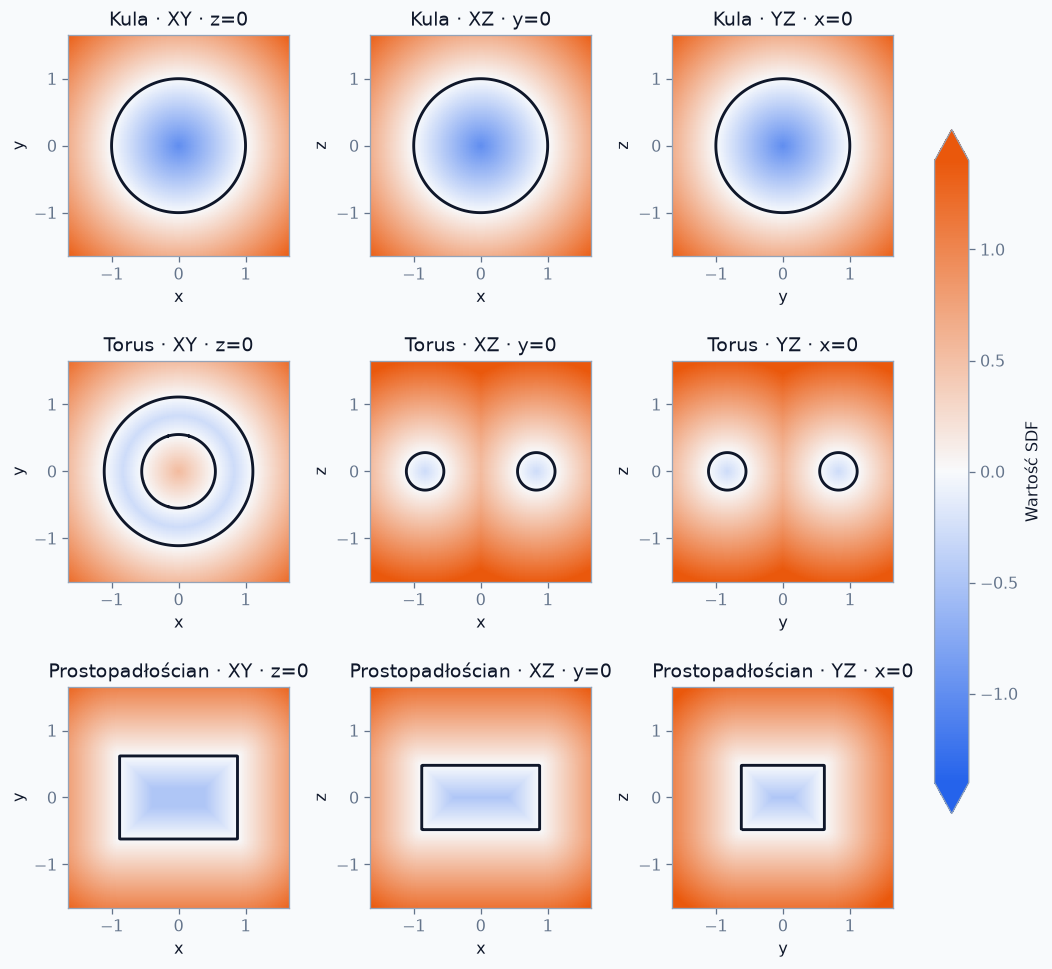

In [18]:
fig, axes = plt.subplots(3, 3, figsize=(9.2, 8.5), layout="constrained")
planes = [
    ((U, V, 0), ("x", "y"), "XY · z=0"),
    ((U, 0, V), ("x", "z"), "XZ · y=0"),
    ((0, U, V), ("y", "z"), "YZ · x=0"),
]
for row, (name, sdf) in zip(axes, SHAPES_3D.items()):
    for panel, (points, labels, plane) in zip(row, planes):
        field = sdf(*points)
        image = field_map(panel, U, V, field, 1.4)
        draw_level(panel, U, V, field)
        plane_axes(panel, f"{name} · {plane}", DOMAIN_3D, labels)
fig.colorbar(image, ax=axes.ravel().tolist(), label="Wartość SDF", shrink=0.75, extend="both")
show_figure(fig)

## 7. Marching Cubes

Zamiast czterech narożników kwadratu klasyfikujemy osiem narożników sześcianu. Na przeciętych krawędziach wyznaczamy wierzchołki, a ich połączenia tworzą trójkąty. Użyjemy wariantu Lewinera z scikit-image.

1. Wybieramy analityczne pole z sekcji 6.
2. Budujemy osie regularnej siatki i porządkujemy tablicę jako `field[ix, iy, iz]`.
3. Próbkujemy pole w węzłach i zapisujemy wartości jako `float32`.
4. Za pomocą `marching_cubes` wyznaczamy powierzchnię dla wybranego poziomu pola $\ell$.
5. Otrzymujemy `vertices` i `faces`. Każdy wiersz `faces` zawiera trzy indeksy wierzchołków.
6. Wyświetlamy mesh w Plotly.

Parametr `spacing` przelicza indeksy na jednostki przestrzenne. Do zwróconych wierzchołków dodajemy jeszcze początek siatki $\mathbf o$. Współrzędne odpowiadają przekształceniu $\mathbf p=\mathbf o+\mathbf h\odot\mathbf i$, gdzie $\mathbf h$ zawiera odstępy na osiach. Demonstracja szuka podziału na wartości poniżej i powyżej poziomu, więc skrajne wartości pola również zgłasza jako brak powierzchni.

In [19]:
def sample_volume(sdf, samples_per_axis, bounds=BOUNDS_3D):
    '''Zwraca pole, fizyczne odstępy węzłów i położenie pierwszego węzła.'''
    axes = [np.linspace(low, high, samples_per_axis) for low, high in bounds]
    spacing = tuple(axis[1] - axis[0] for axis in axes)
    origin = np.array([axis[0] for axis in axes])
    x, y, z = np.meshgrid(*axes, indexing="ij", sparse=True)
    shape = (samples_per_axis,) * 3
    field = np.array(np.broadcast_to(sdf(x, y, z), shape), dtype=np.float32, order="C")
    return field, spacing, origin


def extract_surface(field, spacing, origin, level=0):
    if not field.min() < level < field.max():
        return np.empty((0, 3)), np.empty((0, 3), dtype=int)

    vertices, faces, _, _ = marching_cubes(
        field, level=level, spacing=spacing, gradient_direction="ascent",
        allow_degenerate=False, method="lewiner",
    )
    vertices = vertices + origin
    # Uporządkowanie wierzchołków dla normalnych na zewnątrz w prawoskrętnym XYZ.
    faces = faces[:, ::-1].copy()
    return vertices, faces


def timed_reconstruction(sdf, samples_per_axis, level=0):
    start = perf_counter()
    field, spacing, origin = sample_volume(sdf, samples_per_axis)
    sampling_ms = (perf_counter() - start) * 1000
    start = perf_counter()
    vertices, faces = extract_surface(field, spacing, origin, level)
    marching_ms = (perf_counter() - start) * 1000
    return field, vertices, faces, sampling_ms, marching_ms

In [20]:
def plot_mesh_edges(vertices, faces):
    '''Każda krawędź trójkątów występuje raz, a NaN rozdziela odcinki.'''
    edges = faces[:, [[0, 1], [1, 2], [2, 0]]].reshape(-1, 2)
    edges = np.unique(np.sort(edges, axis=1), axis=0)
    triangles = vertices[faces]
    normals = np.cross(triangles[:, 1] - triangles[:, 0],
                       triangles[:, 2] - triangles[:, 0])
    vertex_normals = np.zeros_like(vertices)
    np.add.at(vertex_normals, faces.ravel(), np.repeat(normals, 3, axis=0))
    lengths = np.linalg.norm(vertex_normals, axis=1, keepdims=True)
    vertex_normals /= np.maximum(lengths, np.finfo(float).eps)
    # Odsunięcie samych linii zapobiega migotaniu między linią a powierzchnią.
    display_vertices = vertices + 0.003 * vertex_normals
    lines = np.full((len(edges), 3, 3), np.nan)
    lines[:, :2] = display_vertices[edges]
    return lines.reshape(-1, 3).T


mesh_figure = go.FigureWidget([
    go.Mesh3d(color=TEAL, flatshading=True, hoverinfo="skip", showlegend=False,
              lighting=dict(ambient=0.63, diffuse=0.65, specular=0, roughness=1)),
    go.Scatter3d(mode="lines", line=dict(color="#084740", width=1),
                 hoverinfo="skip", showlegend=False, visible=False),
])
mesh_figure.update_layout(
    height=480, margin=dict(l=0, r=0, t=0, b=0), paper_bgcolor=BG,
    font=dict(family="DejaVu Sans", color=INK),
    scene=dict(
        aspectmode="cube", uirevision="mesh-camera",
        **{f"{axis}axis": dict(title=axis, range=DOMAIN_3D, backgroundcolor=BG, gridcolor=GRID)
           for axis in "xyz"},
    ),
)

mesh_object = widgets.Dropdown(description="Obiekt", options=list(SHAPES_3D), value="Torus")
mesh_resolution = widgets.Dropdown(
    description="Próbki / oś", options=[16, 24, 32, 48, 64, 96, 128], value=32,
    style={"description_width": "initial"},
)
mesh_level = float_slider("Poziom pola", 0, -1.2, 0.45, 0.025)
mesh_edges = widgets.Checkbox(description="Pokaż krawędzie trójkątów", value=False, indent=False)
mesh_status = widgets.HTML()


def update_mesh(_change=None):
    level = mesh_level.value
    sdf = SHAPES_3D[mesh_object.value]
    field, vertices, faces, sampling_ms, marching_ms = timed_reconstruction(
        sdf, mesh_resolution.value, level
    )
    surface, edges = mesh_figure.data
    with mesh_figure.batch_update():
        surface.x, surface.y, surface.z = vertices.T
        surface.i, surface.j, surface.k = faces.T
        edges.x, edges.y, edges.z = plot_mesh_edges(vertices, faces)
    status = (
        f"<strong>{field.size:,}</strong> próbek · <strong>{len(vertices):,}</strong> "
        f"wierzchołków · <strong>{len(faces):,}</strong> trójkątów<br>"
        f"Pole: {field.nbytes / 2**20:.3f} MiB · Próbkowanie: {sampling_ms:.2f} ms · "
        f"Marching Cubes: {marching_ms:.2f} ms"
    ).replace(",", "\u202f")
    if not len(faces):
        status += (
            f"<br><strong>Brak powierzchni dla {level:+.3f}.</strong> "
            f"Zakres próbek: [{field.min():+.3f}, {field.max():+.3f}]."
        )
    mesh_status.value = status


def toggle_mesh_edges(change):
    mesh_figure.data[1].visible = change["new"]


for control in (mesh_object, mesh_resolution, mesh_level):
    control.observe(update_mesh, names="value")
mesh_edges.observe(toggle_mesh_edges, names="value")
update_mesh()
display(widgets.VBox([
    widgets.HBox([mesh_object, mesh_resolution], layout=widgets.Layout(flex_flow="row wrap")),
    mesh_level, mesh_edges, mesh_status, mesh_figure,
]))

## 8. Wpływ rozdzielczości na rekonstrukcję

Rekonstruujemy ten sam torus dla $16^3,32^3,64^3,128^3$ próbek. Zakres przestrzenny, poziom zero, parametry torusa i widok pozostają stałe. Pole ma $n^3$ wartości i $(n-1)^3$ komórek. Podwojenie liczby próbek na oś zwiększa pamięć tablicy wejściowej ośmiokrotnie. Trójkąty powstają tylko w komórkach, przez które przechodzi powierzchnia, więc ich liczba zależy też od kształtu i wybranego poziomu.

Błąd szacujemy z 20 000 punktów na powierzchni każdego mesha. Losujemy trójkąty z prawdopodobieństwem proporcjonalnym do pola ich powierzchni i wybieramy punkt jednostajnie wewnątrz każdego wylosowanego trójkąta. Średnia $|f_{\mathrm{torus}}|$ szacuje odległość od mesha do powierzchni analitycznej. Ten pomiar opisuje jeden kierunek i może pominąć brakujący fragment powierzchni.

Czasy są mierzone podczas bieżącego uruchomienia, bez rysowania i szacowania błędu. Pamięć oznacza rozmiar samej tablicy `float32`.

In [21]:
def mean_surface_error(vertices, faces, sdf, count=20_000):
    triangles = vertices[faces]
    ab = triangles[:, 1] - triangles[:, 0]
    ac = triangles[:, 2] - triangles[:, 0]
    areas = 0.5 * np.linalg.norm(np.cross(ab, ac), axis=1)
    rng = np.random.default_rng(42)
    selected = rng.choice(len(faces), size=count, p=areas / areas.sum())
    uv = rng.random((count, 2))
    outside = uv.sum(axis=1) > 1
    uv[outside] = 1 - uv[outside]
    points = triangles[selected, 0] + uv[:, :1] * ab[selected] + uv[:, 1:] * ac[selected]
    return np.mean(np.abs(sdf(*points.T)))


resolutions = (16, 32, 64, 128)
experiment_meshes = []
experiment_rows = []
for n in resolutions:
    field, vertices, faces, sampling_ms, marching_ms = timed_reconstruction(torus_sdf, n)
    experiment_meshes.append((vertices, faces))
    experiment_rows.append({
        "Próbki / oś": n,
        "Próbki": field.size,
        "Wierzchołki": len(vertices),
        "Trójkąty": len(faces),
        "Pole [MiB]": field.nbytes / 2**20,
        "Próbkowanie [ms]": sampling_ms,
        "Marching Cubes [ms]": marching_ms,
        "Średni błąd": mean_surface_error(vertices, faces, torus_sdf),
    })

experiment = pd.DataFrame(experiment_rows).set_index("Próbki / oś")
display(experiment.round({
    "Pole [MiB]": 4, "Próbkowanie [ms]": 3, "Marching Cubes [ms]": 3, "Średni błąd": 6,
}))

,Próbki,Wierzchołki,Trójkąty,Pole [MiB],Próbkowanie [ms],Marching Cubes [ms],Średni błąd
Próbki / oś,,,,,,,
16,4096,232,464,0.0156,0.196,0.372,0.017267
32,32768,1240,2480,0.1250,0.316,1.397,0.003878
64,262144,4656,9312,1.0000,2.804,7.064,0.000989
128,2097152,19912,39824,8.0000,21.054,46.458,0.000238


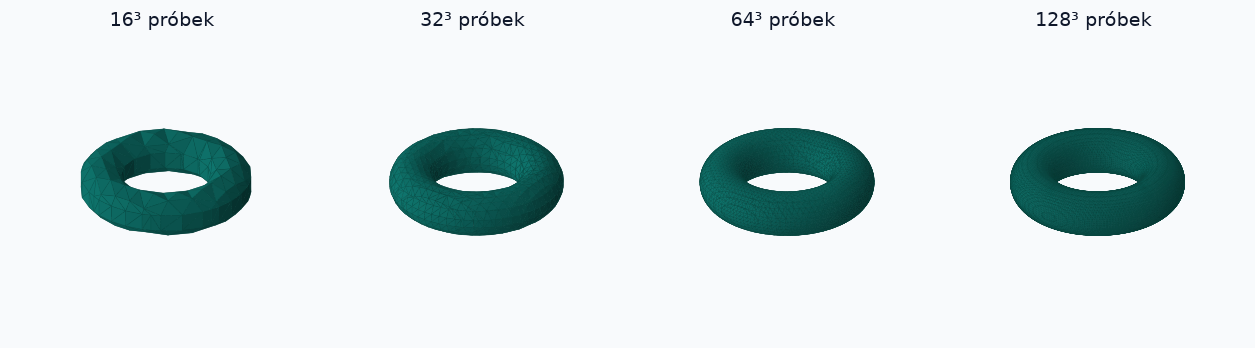

In [22]:
def draw_static_mesh(ax, vertices, faces, title, bounds=DOMAIN_3D, wireframe=False):
    ax.plot_trisurf(
        *vertices.T, triangles=faces, color=TEAL, shade=True,
        edgecolor=(0.03, 0.28, 0.25, 0.32) if wireframe else "none",
        linewidth=0.24 if wireframe else 0,
    )
    ax.set(xlim=bounds, ylim=bounds, zlim=bounds, title=title)
    ax.set_box_aspect((1, 1, 1), zoom=1.45)
    ax.set_proj_type("ortho")
    ax.view_init(elev=29, azim=-56)
    ax.set_axis_off()


fig, axes = plt.subplots(1, 4, figsize=(10.8, 3.2), layout="constrained",
                         subplot_kw={"projection": "3d"})
for panel, n, (vertices, faces) in zip(axes, resolutions, experiment_meshes):
    draw_static_mesh(panel, vertices, faces, f"{n}³ próbek", wireframe=True)
show_figure(fig)

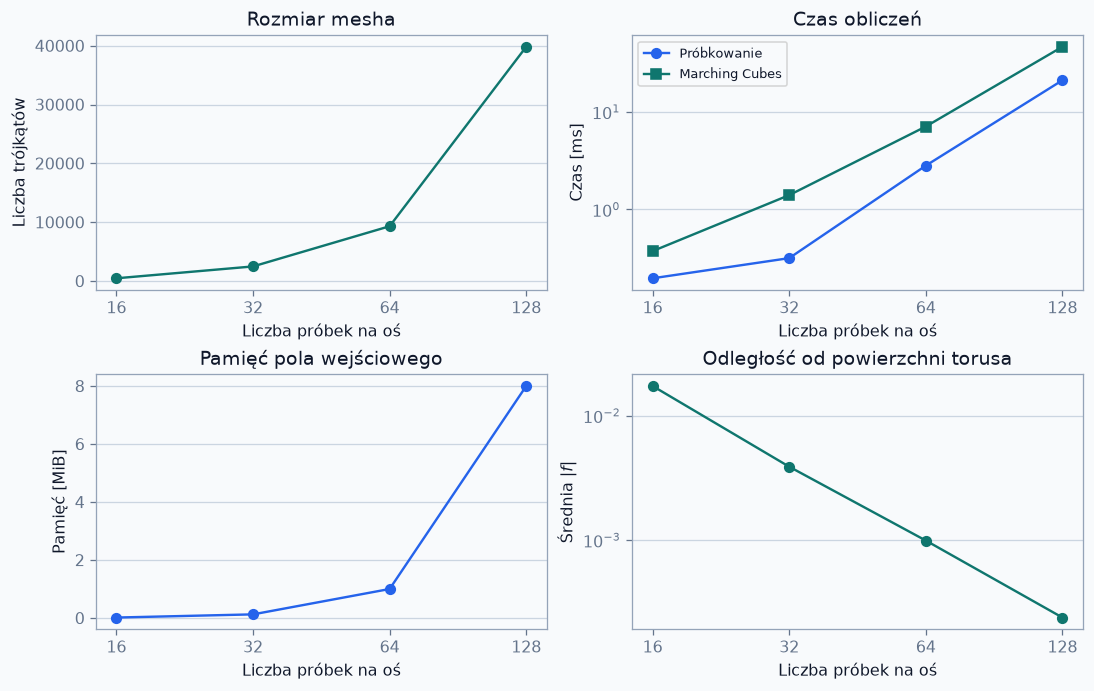

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(9.4, 5.9), layout="constrained")
axes[0, 0].plot(resolutions, experiment["Trójkąty"], "o-", color=TEAL)
axes[0, 0].set(title="Rozmiar mesha", ylabel="Liczba trójkątów")
axes[0, 1].plot(resolutions, experiment["Próbkowanie [ms]"], "o-",
                color=BLUE, label="Próbkowanie")
axes[0, 1].plot(resolutions, experiment["Marching Cubes [ms]"], "s-",
                color=TEAL, label="Marching Cubes")
axes[0, 1].set(title="Czas obliczeń", ylabel="Czas [ms]", yscale="log")
axes[0, 1].legend(fontsize=8)
axes[1, 0].plot(resolutions, experiment["Pole [MiB]"], "o-", color=BLUE)
axes[1, 0].set(title="Pamięć pola wejściowego", ylabel="Pamięć [MiB]")
axes[1, 1].plot(resolutions, experiment["Średni błąd"], "o-", color=TEAL)
axes[1, 1].set(title="Odległość od powierzchni torusa", ylabel=r"Średnia $|f|$", yscale="log")
for ax in axes.flat:
    ax.set(xscale="log", xlabel="Liczba próbek na oś")
    ax.set_xticks(resolutions, labels=[str(n) for n in resolutions])
    ax.minorticks_off()
    ax.grid(axis="y")
show_figure(fig)

## 9. Powierzchnie dla różnych poziomów pola

Dla kuli jednostkowej $f(\mathbf p)=\|\mathbf p\|_2-1$. Warunek $f(\mathbf p)=\ell$ daje promień $1+\ell$, więc dla poziomów $-0{,}3$, $0$ i $+0{,}3$ otrzymujemy promienie $0{,}7$, $1$ i $1{,}3$. Wszystkie trzy meshe powstają z tej samej tablicy próbek. Przekrój analityczny $z=0$ pokazuje ich wzajemne położenie na jednej płaszczyźnie.

Marching Cubes odtwarza powierzchnię dla wybranego poziomu na podstawie próbek pola skalarnego. Pole może opisywać również gęstość, temperaturę lub natężenie sygnału.

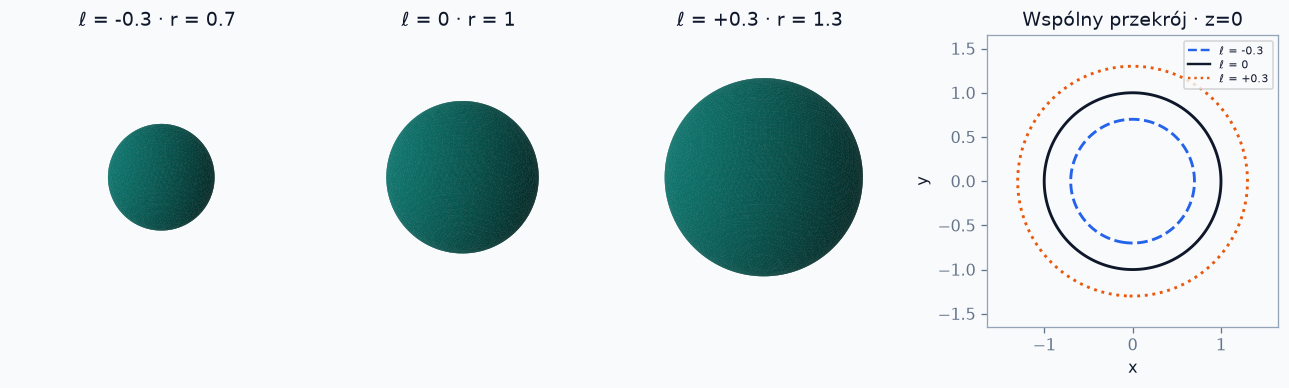

In [24]:
sphere_volume, sphere_spacing, sphere_origin = sample_volume(sphere_sdf, 64)
iso_levels = (-0.3, 0.0, 0.3)
fig = plt.figure(figsize=(11.1, 3.45), layout="constrained")
for index, level in enumerate(iso_levels, start=1):
    panel = fig.add_subplot(1, 4, index, projection="3d")
    vertices, faces = extract_surface(sphere_volume, sphere_spacing, sphere_origin, level)
    label = f"{level:+g}" if level else "0"
    draw_static_mesh(panel, vertices, faces, f"ℓ = {label} · r = {1 + level:g}")

ax = fig.add_subplot(1, 4, 4)
slice_values = sphere_sdf(U, V, 0)
for level, line_style in zip(iso_levels, ("dashed", "solid", "dotted")):
    color = BLUE if level < 0 else ORANGE if level > 0 else INK
    draw_level(ax, U, V, slice_values, level, color=color, linestyle=line_style)
    label = f"{level:+g}" if level else "0"
    ax.plot([], [], color=color, linestyle=line_style, label=f"ℓ = {label}")
plane_axes(ax, "Wspólny przekrój · z=0", DOMAIN_3D)
ax.legend(loc="upper right", fontsize=7, labelspacing=0.2)
show_figure(fig)

## 10. Modelowanie złożonych obiektów

Z prostopadłościanu odejmujemy skończony walec ustawiony wzdłuż osi $z$. W polu wyniku $f_{\mathrm{box}\setminus\mathrm{cyl}}=\max(f_{\mathrm{box}},-f_{\mathrm{cyl}})$ wnętrze prostopadłościanu, które należy do walca, zmienia znak na dodatni. Walec wystaje po obu stronach prostopadłościanu, dlatego otwór jest przelotowy. Dwa przekroje pokazują tę zmianę znaku przed ekstrakcją siatki.

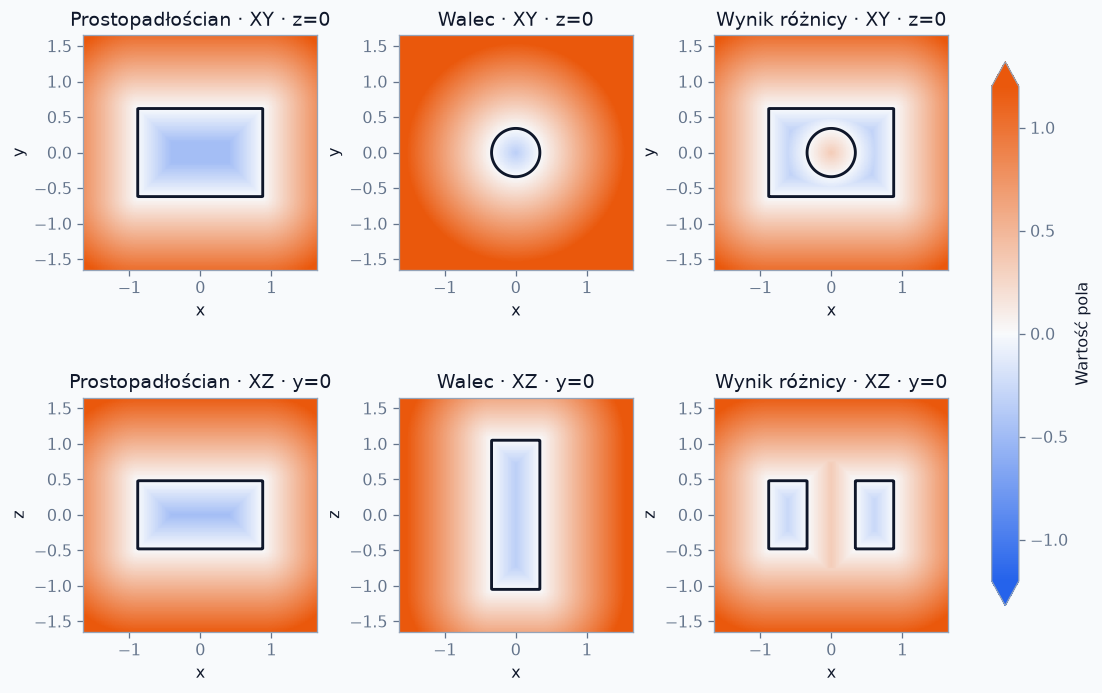

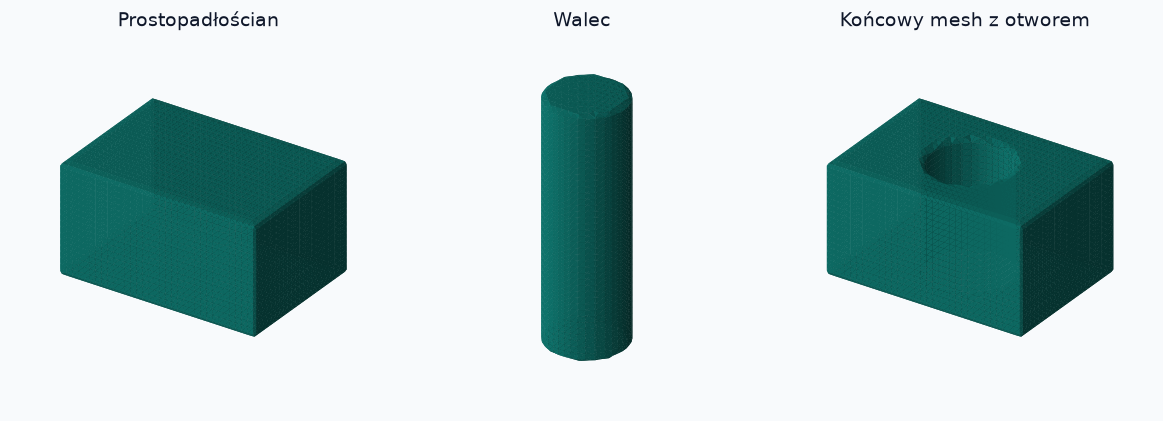

In [25]:
def cylinder_sdf(x, y, z, radius=0.34, half_height=1.05):
    radial = np.hypot(x, y) - radius
    vertical = np.abs(z) - half_height
    outside = np.hypot(np.maximum(radial, 0), np.maximum(vertical, 0))
    return outside + np.minimum(np.maximum(radial, vertical), 0)


def perforated_box(x, y, z):
    return combine_fields(box_sdf(x, y, z), cylinder_sdf(x, y, z), "difference")


fig, axes = plt.subplots(2, 3, figsize=(9.5, 6.3), layout="constrained")
operands = [(box_sdf, "Prostopadłościan"), (cylinder_sdf, "Walec"),
            (perforated_box, "Wynik różnicy")]
for row, (points, labels, plane) in zip(axes, planes[:2]):
    for panel, (sdf, name) in zip(row, operands):
        values = sdf(*points)
        image = field_map(panel, U, V, values, 1.2)
        draw_level(panel, U, V, values)
        plane_axes(panel, f"{name} · {plane}", DOMAIN_3D, labels)
fig.colorbar(image, ax=axes.ravel().tolist(), label="Wartość pola", shrink=0.78, extend="both")
show_figure(fig)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), layout="constrained",
                         subplot_kw={"projection": "3d"})
for panel, (sdf, name) in zip(axes, operands):
    field, spacing, origin = sample_volume(sdf, 64)
    vertices, faces = extract_surface(field, spacing, origin)
    title = "Końcowy mesh z otworem" if sdf is perforated_box else name
    draw_static_mesh(panel, vertices, faces, title, bounds=(-1.2, 1.2))
show_figure(fig)

## 11. Zadanie domowe — połącz dwie kule

Uzupełnij dwie linijki oznaczone `TODO`. Kod ma połączyć dwie kule w jedną bryłę i odtworzyć jej powierzchnię.

1. Zamiast pierwszego `None` wpisz w cudzysłowie nazwę operacji, która łączy obie kule. Nazwy operacji znajdziesz w funkcji `combine_fields` w sekcji 2.
2. Zamiast drugiego `None` wpisz wartość SDF na brzegu obiektu. Przypomnij sobie konwencję znaku z sekcji 1.

Uruchom komórkę. Kod sam narysuje oba meshe dla $16^3$ i $64^3$ próbek i poda liczbę trójkątów nad każdym z nich. Napisz jedno zdanie o tym, jak zmiana rozdzielczości wpłynęła na wynik.

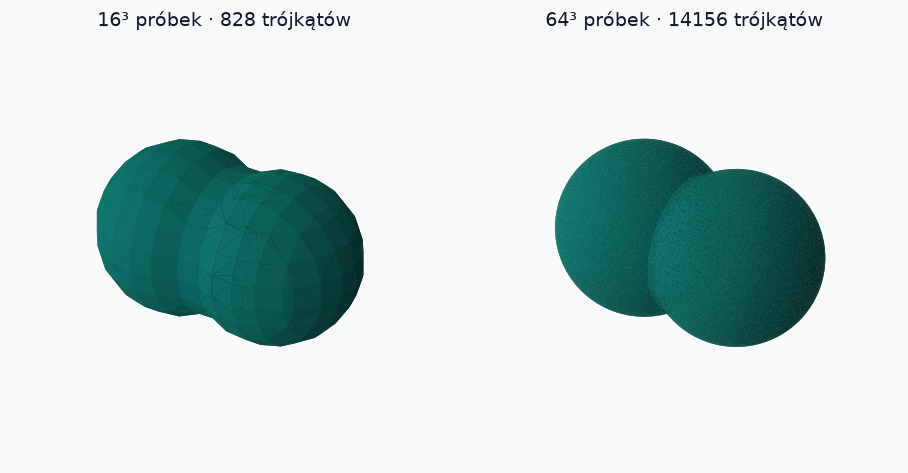

In [28]:
homework_operation = "union"  # TODO 1. Wpisz nazwę operacji w cudzysłowie.
homework_level = 0      # TODO 2. Wpisz poziom pola jako liczbę.


def homework_sdf(x, y, z):
    left = sphere_sdf(x, y, z, center=(-0.5, 0, 0), radius=0.8)
    right = sphere_sdf(x, y, z, center=(0.5, 0, 0), radius=0.8)
    return combine_fields(left, right, homework_operation)


if homework_operation is None or homework_level is None:
    print("Uzupełnij obie linijki TODO, aby zobaczyć wynik.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout="constrained",
                             subplot_kw={"projection": "3d"})
    for ax, n in zip(axes, (16, 64)):
        field, spacing, origin = sample_volume(homework_sdf, n)
        vertices, faces = extract_surface(field, spacing, origin, level=homework_level)
        title = f"{n}³ próbek · {len(faces)} trójkątów"
        if len(faces):
            draw_static_mesh(ax, vertices, faces, title)
        else:
            ax.set_title(title)
            ax.set_axis_off()
    show_figure(fig)

## Źródła

- W. E. Lorensen, H. E. Cline (1987). [Marching Cubes: A High Resolution 3D Surface Construction Algorithm](https://doi.org/10.1145/37402.37422).
- G. M. Nielson, B. Hamann (1991). [The Asymptotic Decider: Resolving the Ambiguity in Marching Cubes](https://doi.org/10.1109/VISUAL.1991.175782).
- scikit-image. [Marching Cubes](https://scikit-image.org/docs/stable/api/skimage.measure.html#skimage.measure.marching_cubes) i [Marching Squares](https://scikit-image.org/docs/stable/auto_examples/edges/plot_contours.html).
- BorisTheBrave (2018). [Marching Cubes 3D Tutorial](https://www.boristhebrave.com/2018/04/15/marching-cubes-3d-tutorial/).